<a id="naive-bayes-classifying-county-migration-inflows"></a>

# Naive Bayes: classifying county migration inflows

Question 9 asks how accurately characteristics classify migration outcomes. This notebook addresses inflow intensity; the decision-tree notebook addresses outflow intensity and net direction.

**Question 9, inflows:** How accurately can characteristics classify inflow intensity? **Input:** the validated analysis dataset. **Cohort:** the shared 2023 county split. **Purpose:** compare retrospective classification with a majority baseline.


<a id="overview"></a>

## Overview

Naive Bayes uses Bayes' rule: P(class | characteristics) is proportional to P(class) times P(characteristics | class). The naive assumption factorizes the latter into feature-wise terms conditional on class. A classifier chooses the class with the largest log posterior score. Correlated housing and economic characteristics can contribute overlapping evidence, so probability estimates deserve caution.

Multinomial NB models nonnegative discrete feature counts and learns each class's relative feature frequencies. Additive smoothing alpha supplies a positive pseudocount, allowing a feature absent in one training class to receive a finite probability. Bernoulli NB models binary feature occurrence and also includes evidence from absence; it is useful for presence/absence indicators. Both learn class priors from labeled training examples by default.

This task uses the required Multinomial NB. Each continuous characteristic is placed into five training-fitted quantile bins and represented by one active indicator. A county contributes one occurrence per characteristic, yielding a fixed-length nonnegative indicator vector. This is a multinomial approximation for binned tabular data: bins discard within-bin variation and related variables may supply redundant evidence.

<a id="data-prep"></a>

## Data Prep

One observation represents one eligible county in 2023. We start with the post-cleaning `analysis_county_year.parquet` and retain the same 3,050 counties used in PCA and clustering. Alaska and Connecticut state substitutes stay outside this county cross-section. Each county receives equal weight. Six counties inherit socioeconomic predictor imputation fitted on 2009–2018 observations; existing outlier flags are retained.

The 13 predictors cover population, age, income, home value, rent, poverty, unemployment, vacancy, homeownership, education, FEMA incidents, precipitation and temperature. Population and monetary values use log10; incidents use log1p. These deterministic transformations precede splitting. Identifiers, migration counts/rates, migration-derived clusters and audit flags are kept outside the feature matrix. Learned transformations are fitted separately within training folds.

A supervised classifier needs labeled examples: a predictor row X and an observed target y. FIPS-sorted counties receive a seeded 80/20 split. Training has 2,440 counties and testing has 610. Their FIPS sets are disjoint, so a county used to fit the classifier cannot also supply its final test score.

Binning migration variables into low/medium/high inflow and outflow each use the training distribution's 1/3 and 2/3 quantiles (linear interpolation). Low includes the first boundary; medium includes the second; high exceeds it. The thresholds define the classification task and remain fixed through cross-validation and test labeling. Net outflow is negative and net inflow positive; the eight exactly balanced counties are reported separately and excluded only from the binary task.

Five shuffled stratified training folds (seed 42) select hyperparameters by mean macro-F1, which weights classes equally. Test results are inspected only after selection.

[Shared profiles and split membership](../website/data/supervised/county-profiles.csv) · [Cohort provenance](../website/data/supervised/context.json)

Samples: [labeled source](../website/data/supervised/nb-labeled-source.csv),
[training characteristics](../website/data/supervised/nb-characteristics-train.csv),
[test characteristics](../website/data/supervised/nb-characteristics-test.csv),
[encoded training inputs](../website/data/supervised/nb-encoded-train.csv), and
[encoded test inputs](../website/data/supervised/nb-encoded-test.csv).
[Training row keys](../website/data/supervised/nb-train-sample-keys.csv) and
[test row keys](../website/data/supervised/nb-test-sample-keys.csv) identify the same rows.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from us_migration.supervised import (FEATURES, LABELS, SEED, RATE_CLASSES, NET_CLASSES,
    prepare_classification, task_rows, export_context, sample, evaluate, figure,
    comparison_plot, tree_structure, records, write_json, configure_plots)
configure_plots()
SOURCE = ROOT / 'data/processed/analysis_county_year.parquet'
counties, X, thresholds = prepare_classification(pd.read_parquet(SOURCE))
from us_migration.exports import begin_analysis, finish_analysis
BUNDLE = begin_analysis(ROOT, 'classification/naive-bayes')
context = export_context(BUNDLE, SOURCE, counties, thresholds)
OUT = BUNDLE/'data'
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
display(pd.DataFrame(thresholds, index=['Low/medium boundary', 'Medium/high boundary']))
display(counties.groupby(['classification_split', 'net_class']).size().unstack(fill_value=0))
assert len(counties) == 3050 and X.shape == (3050, 13)
assert counties.classification_split.value_counts().to_dict() == {'train': 2440, 'test': 610}

,inflow,outflow
Low/medium boundary,39.008023,38.995502
Medium/high boundary,50.447417,47.030690


net_class,Balanced,Net inflow,Net outflow
classification_split,,,
test,0,352,258
train,8,1466,966


,county_fips,county_name,inflow_individuals_per_1000,inflow_class,classification_split
0,01001,"Autauga County, Alabama",73.290040,High,test
1,01003,"Baldwin County, Alabama",58.976015,High,train
2,01005,"Barbour County, Alabama",27.063053,Low,train
3,01007,"Bibb County, Alabama",37.784399,Low,train
4,01009,"Blount County, Alabama",42.197936,Medium,train
5,01011,"Bullock County, Alabama",27.764104,Low,train
6,01013,"Butler County, Alabama",27.223906,Low,train
7,01015,"Calhoun County, Alabama",38.427429,Low,train
8,01017,"Chambers County, Alabama",43.773585,Medium,train
9,01019,"Cherokee County, Alabama",53.679036,High,train


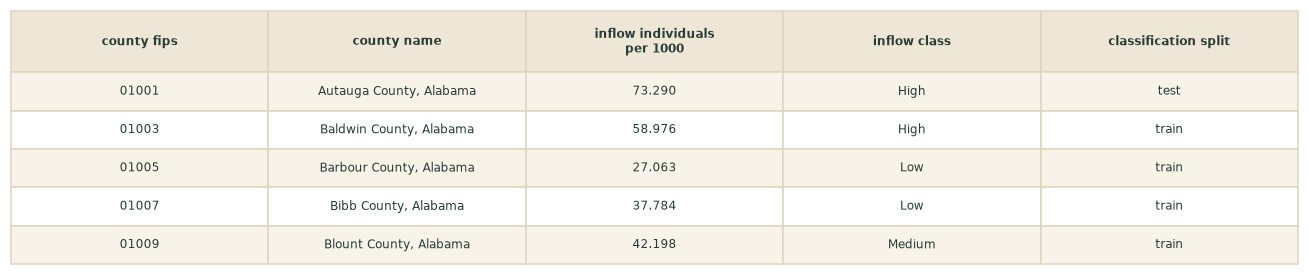

inflow_class
Low       814
Medium    813
High      813
Name: train, dtype: int64

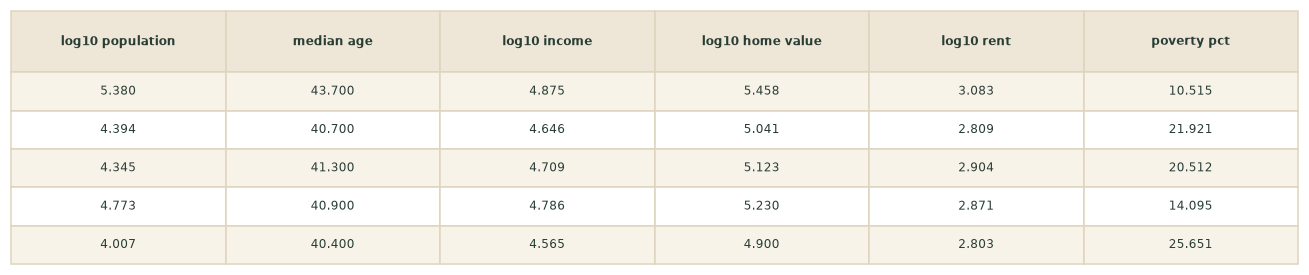

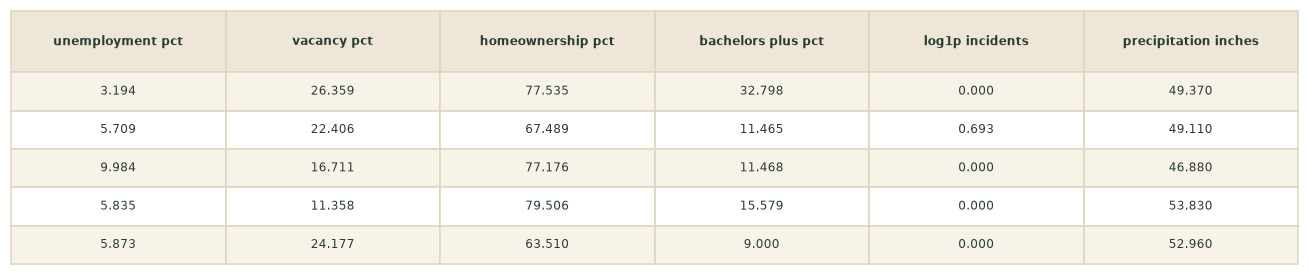

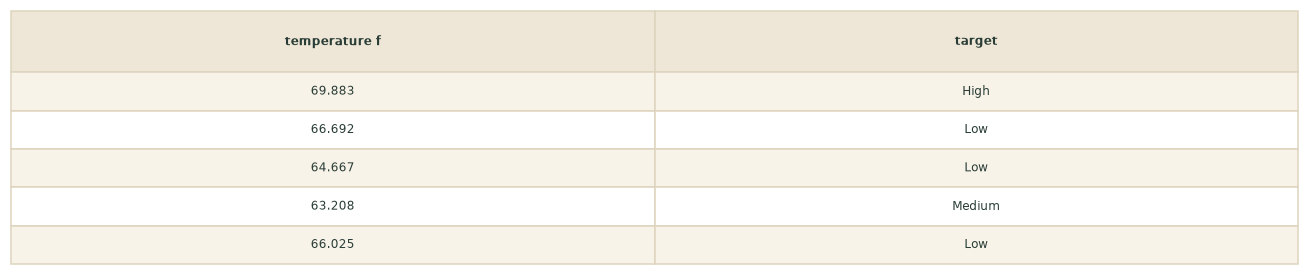

inflow_class
Low       222
Medium    182
High      206
Name: test, dtype: int64

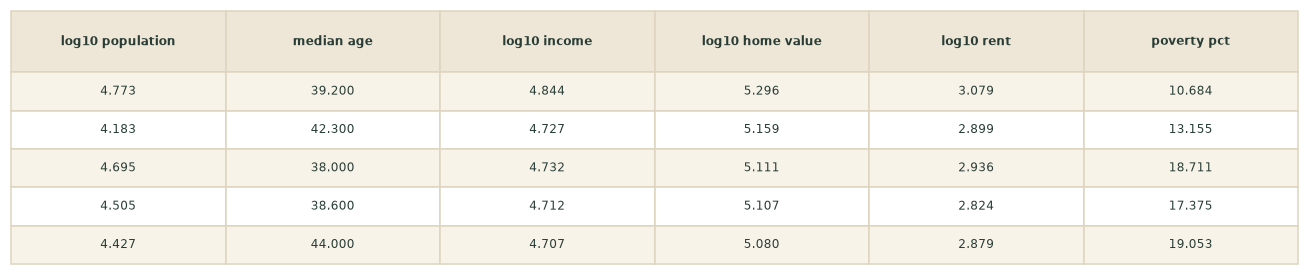

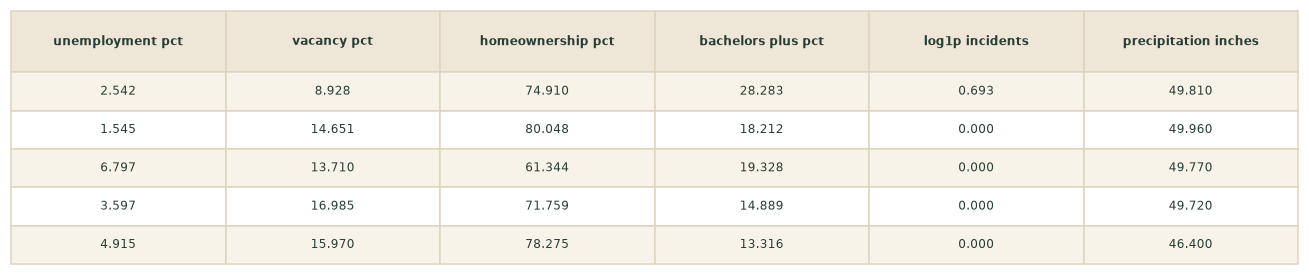

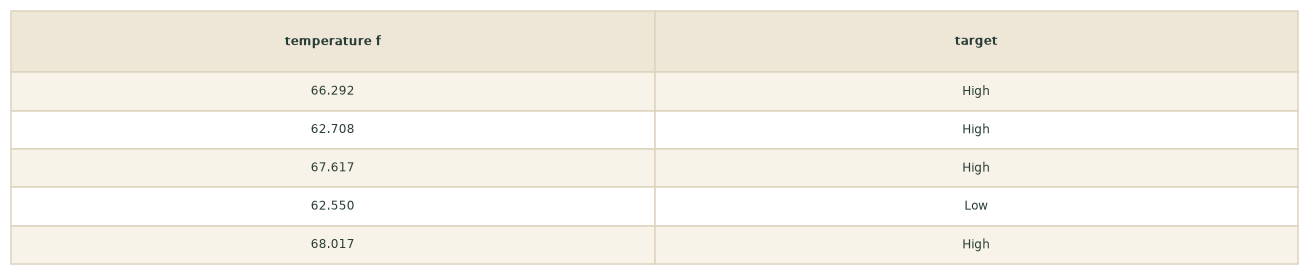

In [2]:
outcome = 'inflow'
x_train, x_test, y_train, y_test = task_rows(counties, X, outcome)
classes = RATE_CLASSES
source_columns = ['county_fips', 'county_name', 'inflow_individuals_per_1000', 'inflow_class', 'classification_split']
display(counties[source_columns].head(20))
samples = [sample(counties[source_columns], BUNDLE, 'nb-labeled-source')]
for split, x, y in [('train', x_train, y_train), ('test', x_test, y_test)]:
    display(y.value_counts().reindex(classes).rename(split))
    samples.append(sample(x.assign(target=y), BUNDLE, 'nb-characteristics-'+split))
    counties.loc[x.sort_index().head(20).index, ['county_fips','county_name','classification_split']].to_csv(OUT/f'nb-{split}-sample-keys.csv', index=False)
assert set(counties.loc[x_train.index, 'county_fips']).isdisjoint(counties.loc[x_test.index, 'county_fips'])

<a id="code"></a>

## Code

The pipeline fits quantile edges only on continuous predictors in each training fold. Duplicate edges collapse rather than dividing identical values across arbitrary categories; effective bin counts are exported. Transform assigns values beyond the training range to the first or last bin. The outcome tertiles and predictor quintile bins serve different purposes.

We compare alpha 0.1, 1 and 10, fixing five requested bins, learned priors and the split. Exact macro-F1 ties favor stronger smoothing. Fold standard deviations describe variability across overlapping training fits; they are descriptive rather than independent confidence intervals.

C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 10 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 10 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 10 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) 

C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 10 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 10 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 10 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\kenny\Data Science Projects\us-migration\us-migration\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) 

,alpha,mean_train_score,mean_test_score,std_test_score
0,1.0,0.513181,0.500537,0.015650
1,0.1,0.513319,0.500375,0.015920
2,10.0,0.511744,0.497857,0.016046


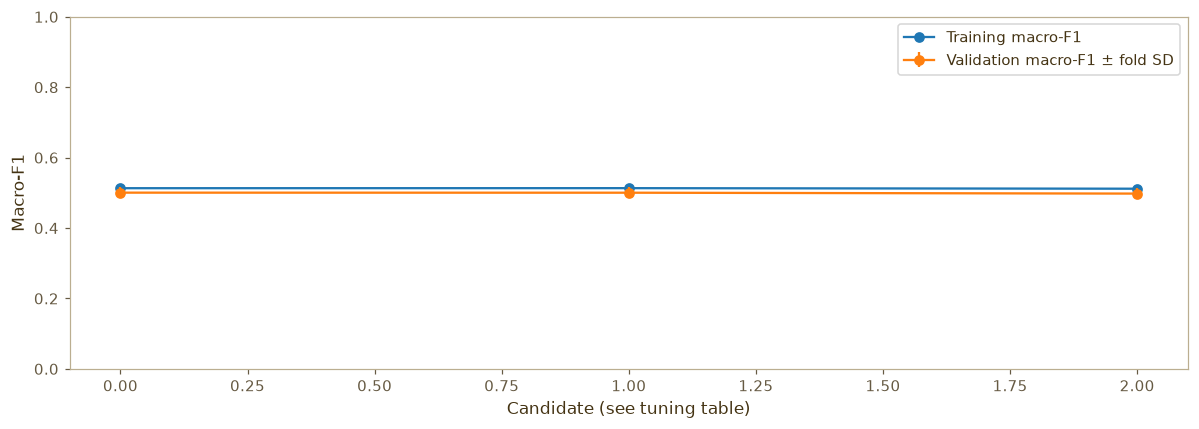

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.naive_bayes import MultinomialNB

pipeline = Pipeline([
    ('bins', KBinsDiscretizer(n_bins=5, encode='onehot', strategy='quantile',
                             quantile_method='linear', subsample=None)),
    ('nb', MultinomialNB(fit_prior=True)),
])
search = GridSearchCV(pipeline, {'nb__alpha': [0.1, 1.0, 10.0]}, cv=cv,
                      scoring='f1_macro', return_train_score=True, refit=False, n_jobs=1)
search.fit(x_train, y_train)
tuning = pd.DataFrame(search.cv_results_)
tuning['alpha'] = tuning.param_nb__alpha.astype(float)
tuning = tuning.sort_values(['mean_test_score', 'alpha'], ascending=[False, False]).reset_index(drop=True)
selected_alpha = float(tuning.iloc[0].alpha)
model = pipeline.set_params(nb__alpha=selected_alpha).fit(x_train, y_train)
baseline = DummyClassifier(strategy='most_frequent').fit(x_train, y_train)
tuning[['alpha', 'mean_train_score', 'mean_test_score', 'std_test_score']].to_csv(OUT/'inflow-tuning.csv', index=False)
display(tuning[['alpha', 'mean_train_score', 'mean_test_score', 'std_test_score']])
comparison_plot(tuning, BUNDLE, 'inflow-comparison')

<a id="model-input-after-binning"></a>

### Model input after binning

The tables below show the actual encoded training and test inputs with target labels. Images show five rows in FIPS order; CSVs retain twenty rows and full precision. Row keys are exported separately. Each transformed row must contain exactly 13 active indicators, one per original characteristic. Cross-validation computes bin cutoffs on each fold's training portion and applies those cutoffs to the validation set. Then after cross-validation selects the model hyperparameters, the binning is performed again on the combined set of training and validation data and the derived cutoffs are applied to the held-out test set.

,log10_population_0.0,log10_population_1.0,log10_population_2.0,log10_population_3.0,log10_population_4.0,median_age_0.0,median_age_1.0,median_age_2.0,median_age_3.0,median_age_4.0,...,precipitation_inches_1.0,precipitation_inches_2.0,precipitation_inches_3.0,precipitation_inches_4.0,temperature_f_0.0,temperature_f_1.0,temperature_f_2.0,temperature_f_3.0,temperature_f_4.0,target
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,High
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,Low
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,Low
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,Medium
5,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,Low


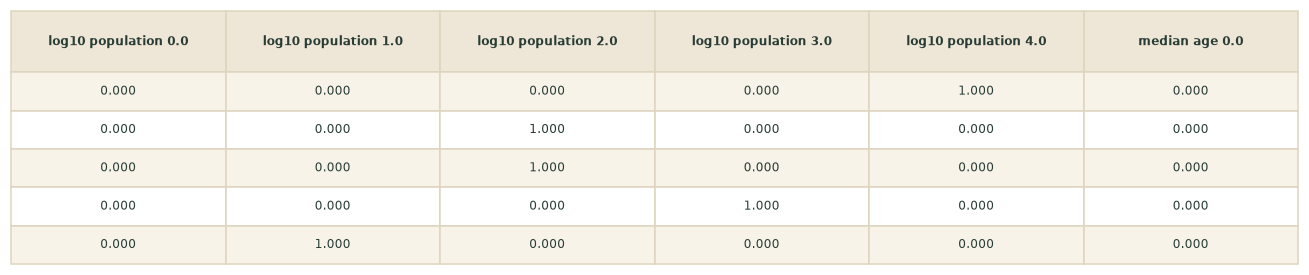

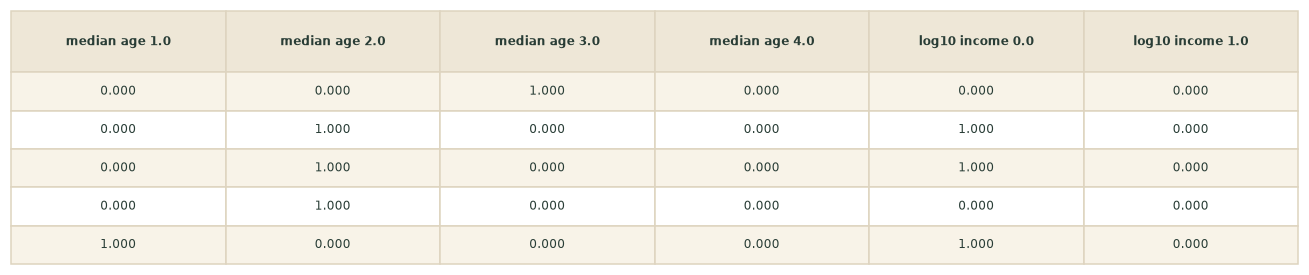

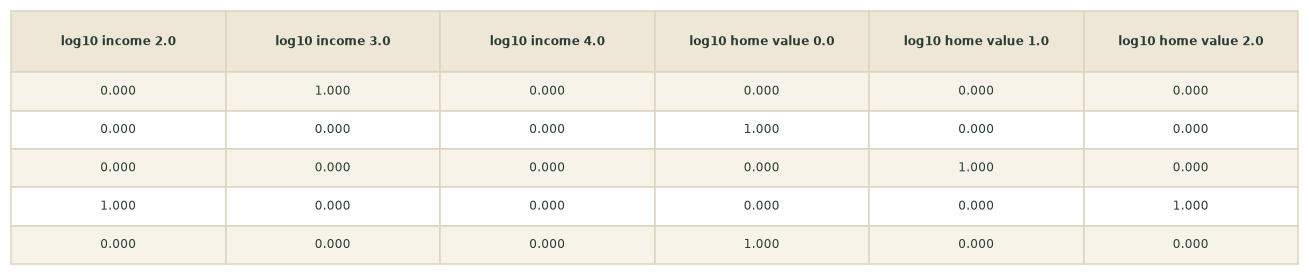

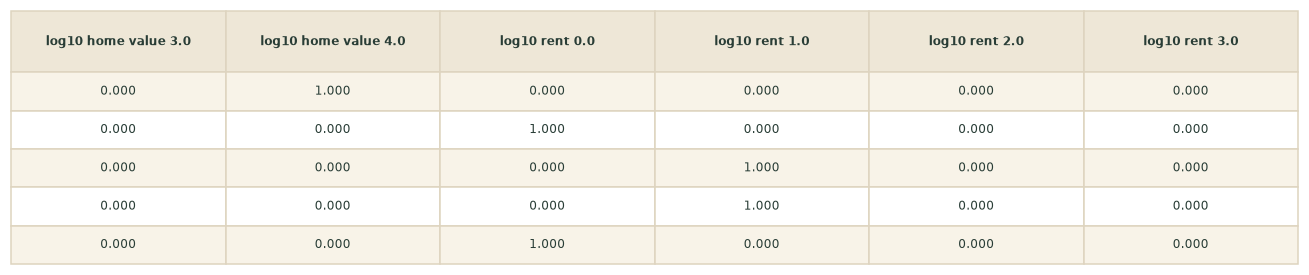

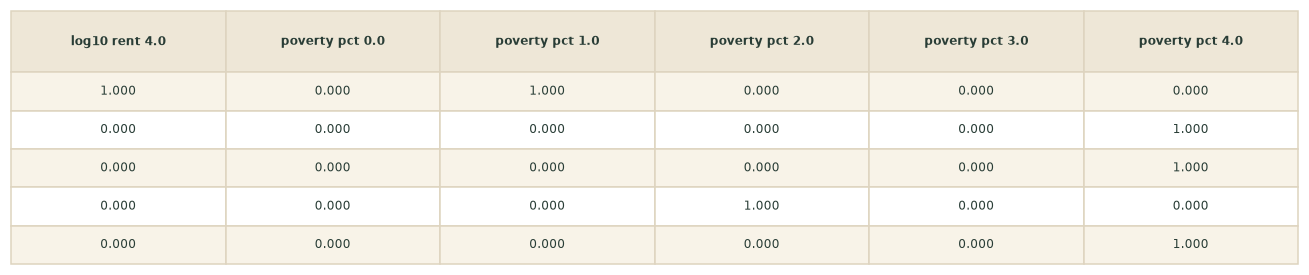

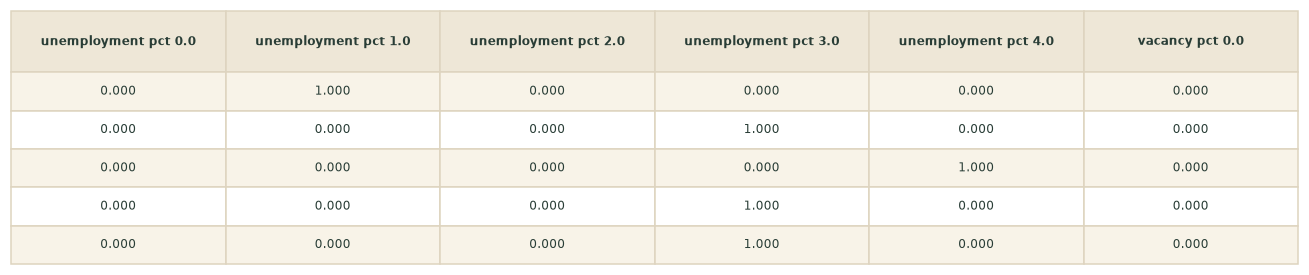

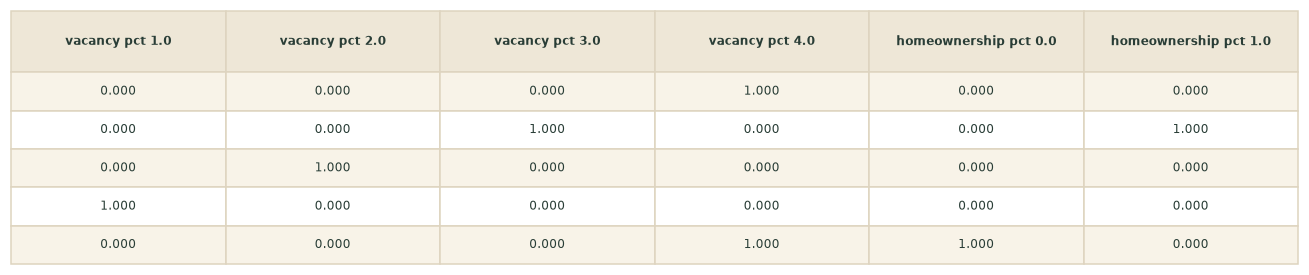

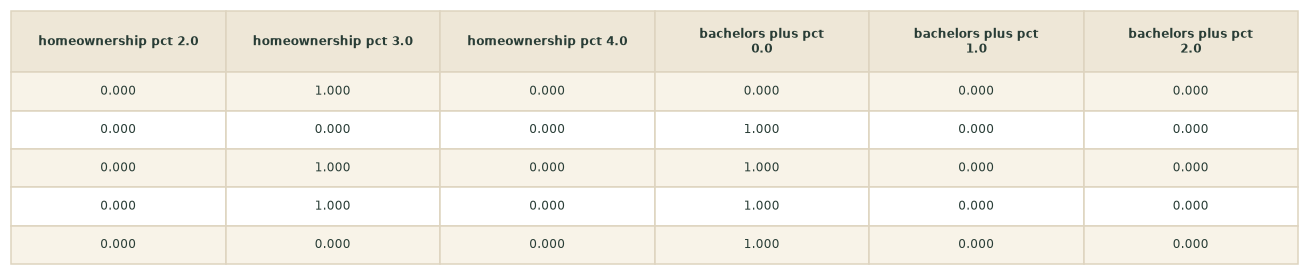

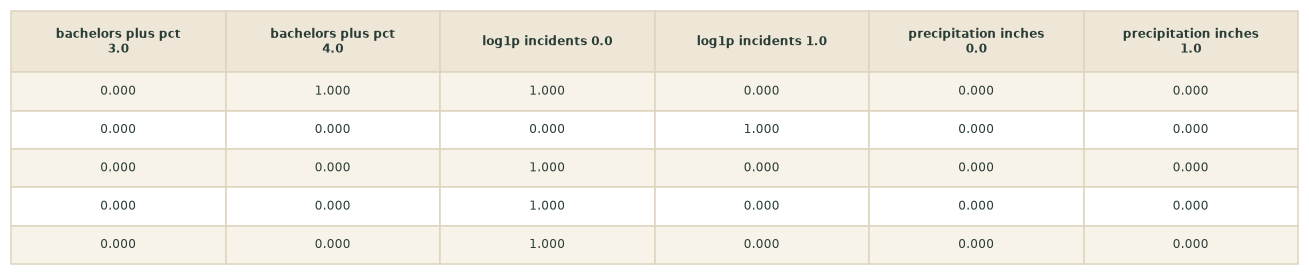

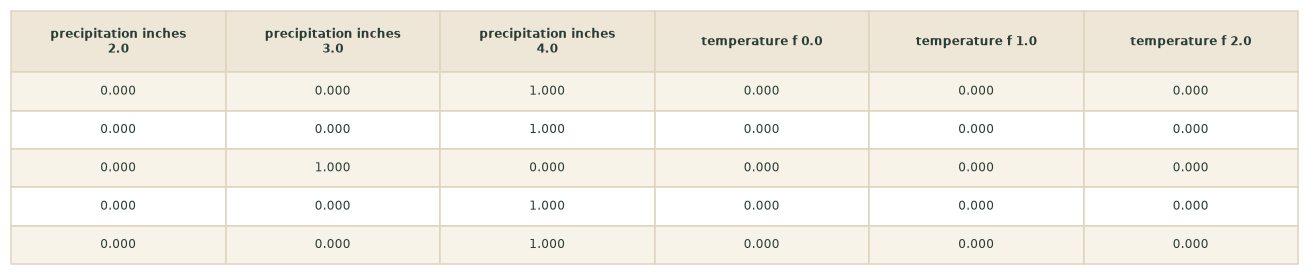

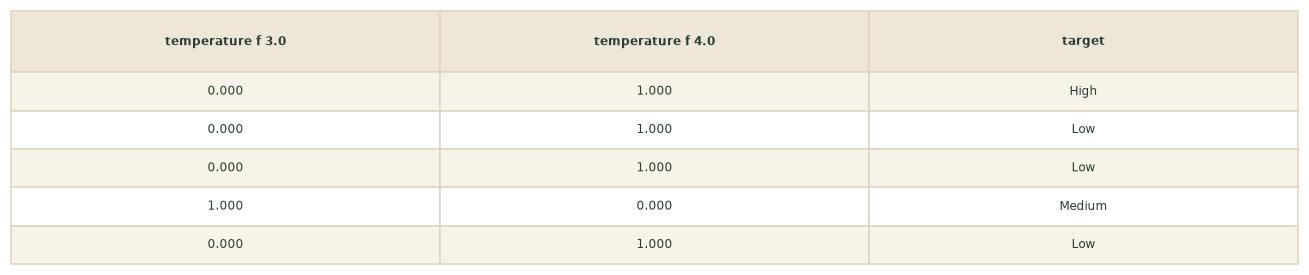

,log10_population_0.0,log10_population_1.0,log10_population_2.0,log10_population_3.0,log10_population_4.0,median_age_0.0,median_age_1.0,median_age_2.0,median_age_3.0,median_age_4.0,...,precipitation_inches_1.0,precipitation_inches_2.0,precipitation_inches_3.0,precipitation_inches_4.0,temperature_f_0.0,temperature_f_1.0,temperature_f_2.0,temperature_f_3.0,temperature_f_4.0,target
0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,High
14,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,High
22,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,High
29,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,Low
30,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,High


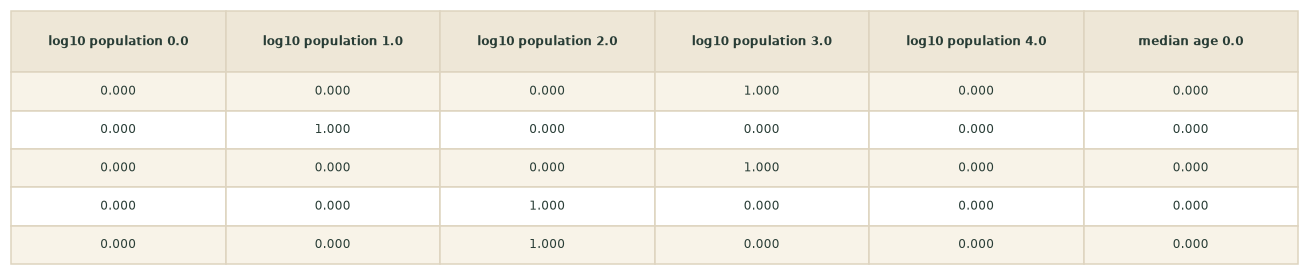

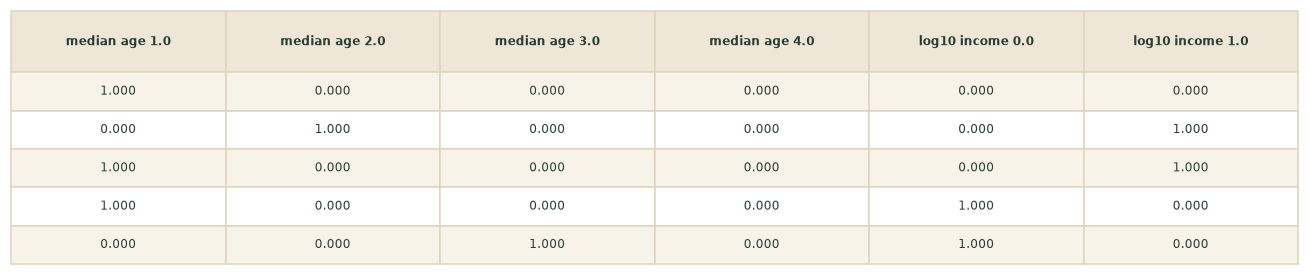

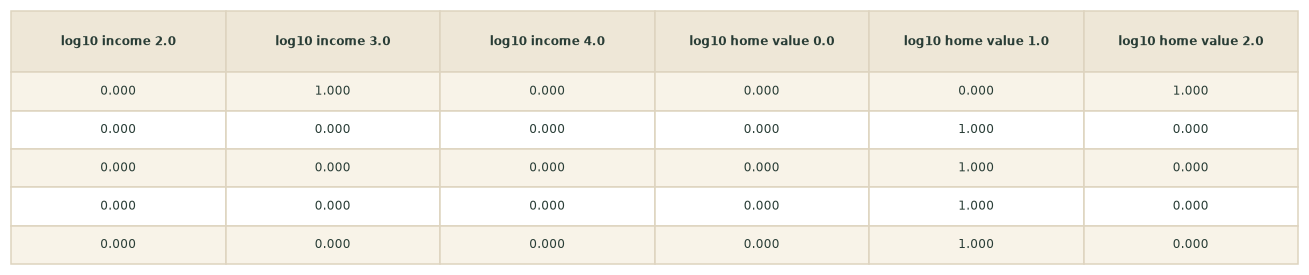

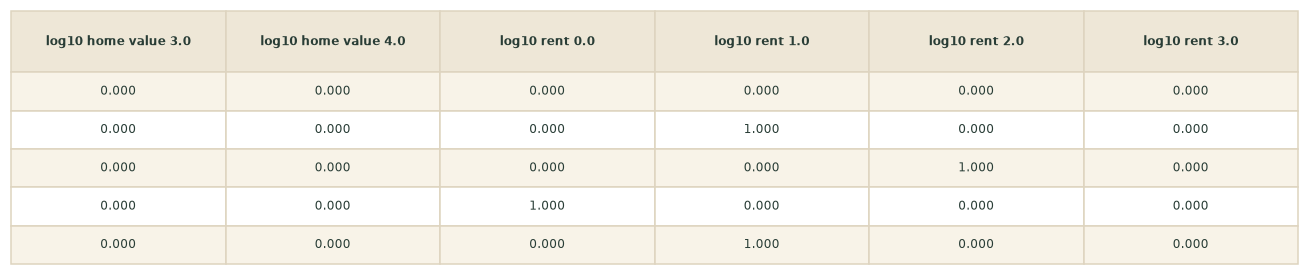

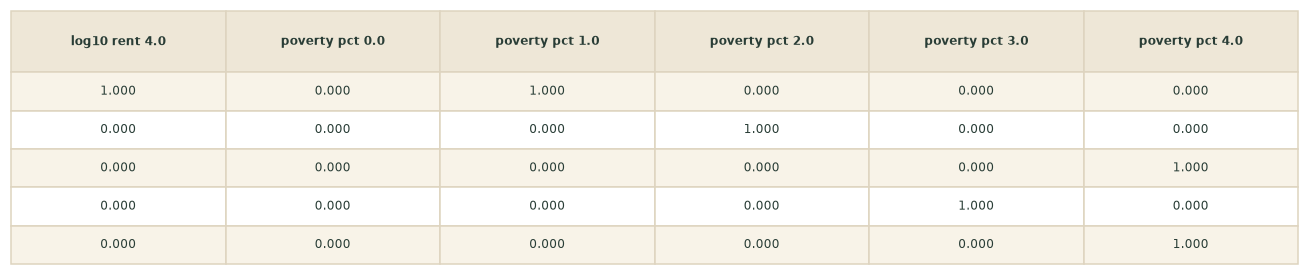

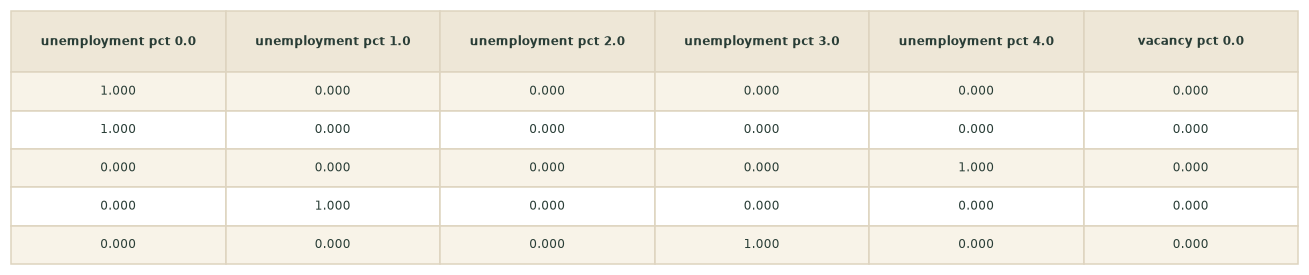

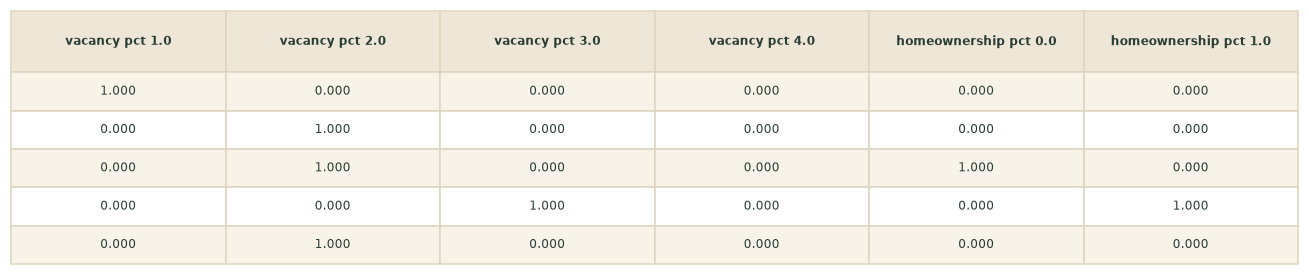

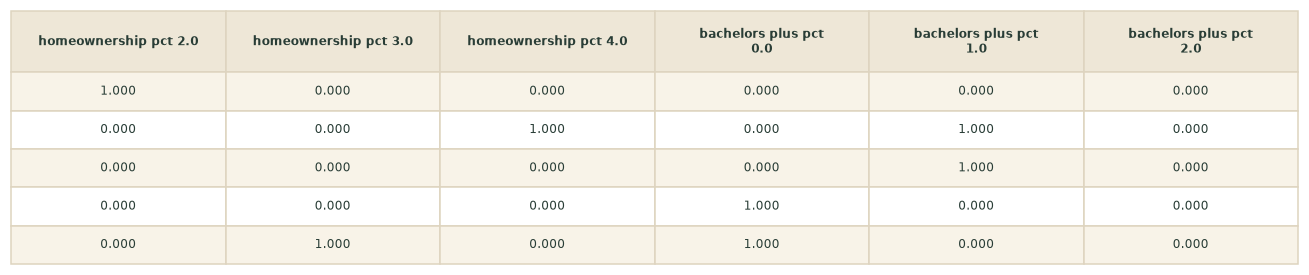

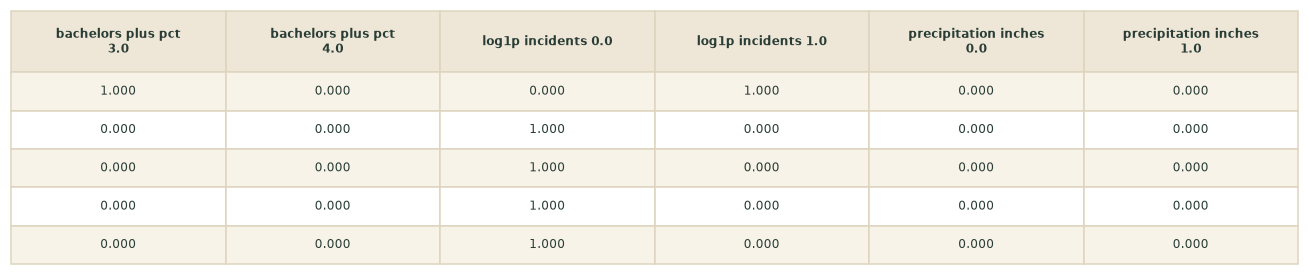

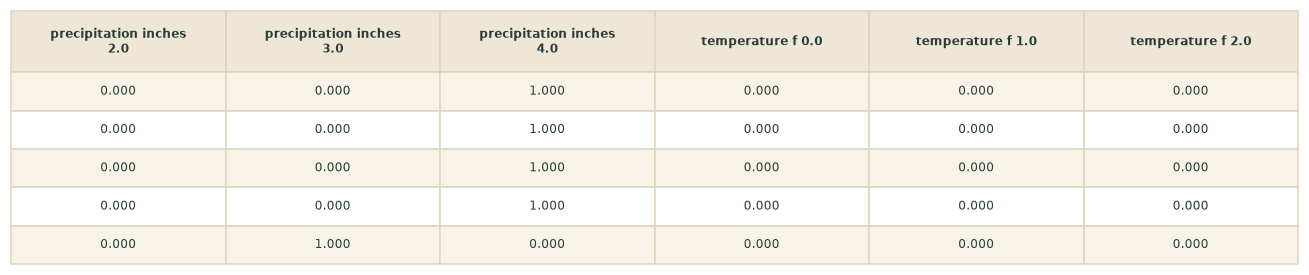

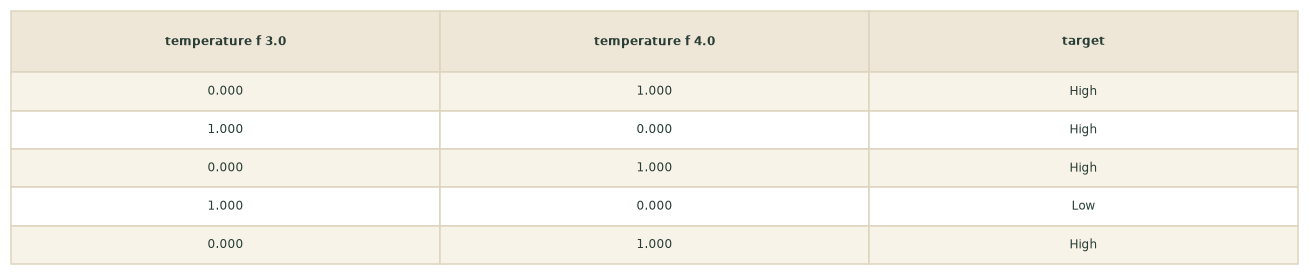

,feature,effective_bins
0,log10_population,5
1,median_age,5
2,log10_income,5
3,log10_home_value,5
4,log10_rent,5
5,poverty_pct,5
6,unemployment_pct,5
7,vacancy_pct,5
8,homeownership_pct,5
9,bachelors_plus_pct,5


In [4]:
encoder = model.named_steps['bins']
feature_names = encoder.get_feature_names_out(FEATURES)
for split, x, y in [('train', x_train, y_train), ('test', x_test, y_test)]:
    encoded = encoder.transform(x).toarray()
    assert np.isfinite(encoded).all() and (encoded >= 0).all()
    assert np.allclose(encoded.sum(axis=1), len(FEATURES))
    frame = pd.DataFrame(encoded, index=x.index, columns=feature_names).assign(target=y)
    display(frame.sort_index().head())
    samples.append(sample(frame, BUNDLE, 'nb-encoded-'+split))
preprocessing = {feature: {'edges': edges.tolist(), 'effective_bins': int(bins)}
                 for feature, edges, bins in zip(FEATURES, encoder.bin_edges_, encoder.n_bins_)}
write_json(OUT/'inflow-preprocessing.json', preprocessing)
display(pd.DataFrame({'feature': FEATURES, 'effective_bins': encoder.n_bins_}))

<a id="results"></a>

## Results

Evaluate the frozen model and training-majority baseline on the same held-out counties. Accuracy counts the fraction classified correctly; balanced accuracy averages class recall. Macro-F1 averages class-specific F1, combining precision and recall. Confusion matrices show where low, medium and high classifications overlap.

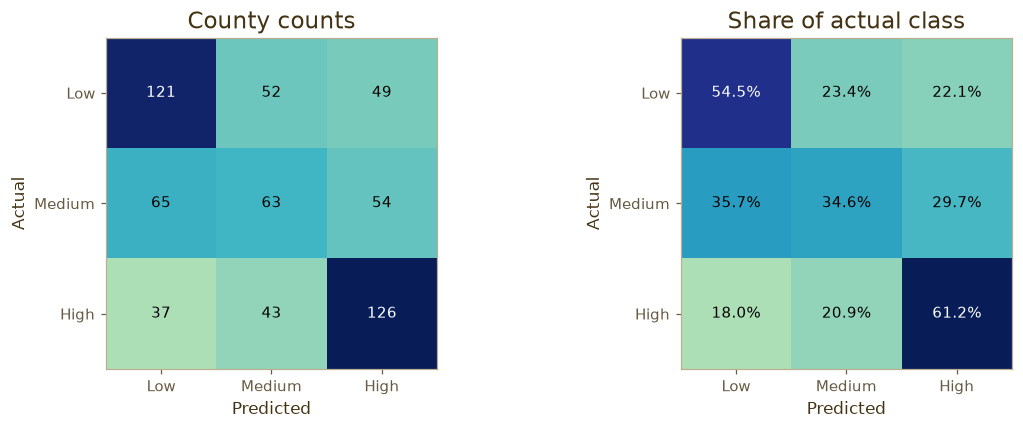

,accuracy,balanced_accuracy,macro_f1
model,0.508197,0.500950,0.497906
baseline,0.363934,0.333333,0.177885


,precision,recall,f1-score,support
Low,0.542601,0.545045,0.543820,222.000000
Medium,0.398734,0.346154,0.370588,182.000000
High,0.550218,0.611650,0.579310,206.000000
accuracy,0.508197,0.508197,0.508197,0.508197
macro avg,0.497184,0.500950,0.497906,610.000000
weighted avg,0.502249,0.508197,0.504120,610.000000


,class,indicator,relative_log_likelihood
0,High,log10_home_value_4.0,0.748475
1,High,log10_rent_4.0,0.672711
2,High,log10_income_4.0,0.558162
3,High,bachelors_plus_pct_4.0,0.548625
4,High,temperature_f_3.0,0.534345
5,Low,log10_home_value_0.0,0.782126
6,Low,log10_rent_0.0,0.659940
7,Low,temperature_f_1.0,0.527507
8,Low,log10_population_0.0,0.453302
9,Low,log10_home_value_1.0,0.359086


In [5]:
result = evaluate(model, baseline, x_test, y_test, classes, counties, BUNDLE, outcome)
result.update(outcome=outcome, selected={'alpha': selected_alpha},
              train_count=len(x_train), test_count=len(x_test), samples=samples,
              tuning=records(tuning[['alpha', 'mean_train_score', 'mean_test_score', 'std_test_score']]),
              preprocessing=preprocessing,
              selected_cv_macro_f1=float(tuning.iloc[0].mean_test_score),
              selected_train_macro_f1=float(tuning.iloc[0].mean_train_score))
display(pd.DataFrame({k:{m:v[m] for m in ['accuracy','balanced_accuracy','macro_f1']} for k,v in result.items() if k in ['model','baseline']}).T)
display(pd.DataFrame(result['model']['classification_report']).T)
# Rank indicator associations relative to their mean log likelihood across classes.
log_likelihood = model.named_steps['nb'].feature_log_prob_
relative = log_likelihood - log_likelihood.mean(axis=0)
patterns = []
for i, cls in enumerate(model.classes_):
    for j in np.argsort(relative[i])[-5:][::-1]:
        patterns.append({'class': cls, 'indicator': feature_names[j],
                         'relative_log_likelihood': float(relative[i,j])})
pd.DataFrame(patterns).to_csv(OUT/'inflow-indicator-patterns.csv', index=False)
result['patterns'] = patterns
display(pd.DataFrame(patterns))

<a id="conclusions"></a>

## Conclusions

The following findings are calculated from the executed evaluation. Indicator patterns describe the fitted model's relative class associations; correlated predictors, discretization and the naive factorization constrain interpretation. Their weights describe predictive associations rather than causal effects. This inflow result forms one part of question 9; the website Findings chapter brings all three targets together.

In [6]:
m, b = result['model'], result['baseline']
weakest = min(classes, key=lambda c: m['classification_report'][c]['recall'])
result['conclusions'] = [
    f"The selected Multinomial NB (alpha {selected_alpha:g}) correctly classifies {m['accuracy']:.1%} of {len(x_test):,} held-out counties by inflow-rate tertile; the majority baseline achieves {b['accuracy']:.1%}.",
    f"Macro-F1 is {m['macro_f1']:.3f}, compared with baseline {b['macro_f1']:.3f}; balanced accuracy is {m['balanced_accuracy']:.1%}. The {weakest.lower()} class has the lowest recall ({m['classification_report'][weakest]['recall']:.1%}).",
    f"Selected mean training-fold macro-F1 is {result['selected_train_macro_f1']:.3f} and validation macro-F1 is {result['selected_cv_macro_f1']:.3f}. This gap describes how the fitted specification transfers to held-out training folds.",
    'Rate tertiles describe relative inflow intensity among training counties. These contemporaneous associations support retrospective classification; spatial dependence, prior exploration, source coverage and binning limit claims about future migration.'
]
for text in result['conclusions']: display(Markdown(text))
write_json(OUT/'naive-bayes.json', {'context': context, 'tasks': {'inflow': result}})
finish_analysis(ROOT, 'classification/naive-bayes', BUNDLE)


The selected Multinomial NB (alpha 1) correctly classifies 50.8% of 610 held-out counties by inflow-rate tertile; the majority baseline achieves 36.4%.

Macro-F1 is 0.498, compared with baseline 0.178; balanced accuracy is 50.1%. The medium class has the lowest recall (34.6%).

Selected mean training-fold macro-F1 is 0.513 and validation macro-F1 is 0.501. This gap describes how the fitted specification transfers to held-out training folds.

Rate tertiles describe relative inflow intensity among training counties. These contemporaneous associations support retrospective classification; spatial dependence, prior exploration, source coverage and binning limit claims about future migration.

<a id="reading-connections"></a>

## Reading connections

The measured conclusions above answer the inflow portion of question 9. [Decision trees](decision_trees.ipynb) address outflows and net direction independently; website export assembles the combined evidence.
